In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import random
import types

from time import time

from scipy.special import comb, loggamma, lambertw
from scipy.stats import multinomial, expon

from silence_tensorflow import silence_tensorflow
silence_tensorflow()
import tensorflow as tf
import tensorflow_probability as tfp
from tensorflow import keras
from tensorflow.keras import optimizers, initializers, regularizers, layers

config = tf.compat.v1.ConfigProto()
config.gpu_options.allow_growth = True
sess = tf.compat.v1.Session(config = config)

import os, shutil
from pathlib import Path
import json
import subprocess

import lifelines
from lifelines.utils import concordance_index
from lifelines.statistics import logrank_test

import sys
sys.path.insert(0, "../src")
from package import cure_aft
from package import gndr_utils as utils
from package import evaluation_metrics as evaluations

import thetaflow as thf

E0000 00:00:1793906154.706570   49391 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793906154.711554   49391 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793906154.724337   49391 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793906154.724359   49391 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793906154.724361   49391 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793906154.724362   49391 computation_placer.cc:177] computation placer already registered. Please check linka

### Motivation

In this notebook, we consider a final application of the AFTcr-NN model given by assuming a Log-normal distribution for the lifetimes. For the susceptible patient group we assume
\begin{equation}
    \log T_i = \mu_i + \sigma_i T_0,
\end{equation}
where $T_0 \sim N(0,1)$. That results in the survival and density functions being represented, respectively as
\begin{align}
    S_{1i}(t; \mu_i, \sigma_i) &= 1 - \Phi(z_i(t)),\\
	f_{1i}(t; \mu_i, \sigma_i) &= \frac{1}{t \sigma_i \sqrt{2\pi}} \exp\left\{-\frac{1}{2} z_i(t)^2\right\},
\end{align}

Then, for any given patient, we assume there is a probability they are immune from the cancer recurrence, or that $T_i = \infty$. That assumption is directly reflected in the final survival and density curves described as
\begin{align}
    S_i(t; \mu_i, \sigma_i, p_i) &= p_i + (1-p_i) S_{1i}(t; \mu_i, \sigma_i),\\
	f_i(t; \mu_i, \sigma_i, p_i) &= (1-p_i) f_{1i}(t; \mu_i, \sigma_i).
\end{align}

Finally, after the analysis of Cross-validated results, we will consider the selected model, that assumes:
\begin{align}
    \mu_i &= \boldsymbol z_{\mu_i} \boldsymbol \beta_\mu,\\
	\sigma_i &= \boldsymbol z_{\sigma_i} \boldsymbol \beta_\sigma,\\
    p_i &= \boldsymbol z_{p_i} \boldsymbol \beta_p + \mathcal{F}(\boldsymbol x_i; \boldsymbol \omega),
\end{align}
where $\mathcal{F}(\boldsymbol x_i ; \boldsymbol \omega)$ is a neural network and $\boldsymbol x_i$ represents the vector of mutation counts for each of the 173 genes mapped in the METABRIC dataset.

Here, we will not be considering a hold-out train-test analysis, since we already validated this to be our winning model.

In [2]:
df_clean_train = pd.read_csv("../data/00_clean/metabric_train_data.csv")
df_clean_test = pd.read_csv("../data/00_clean/metabric_test_data.csv")
df_clean = pd.concat([df_clean_train, df_clean_test], axis = 0).reset_index(drop = True)

df_train = pd.read_csv("../data/01_mlready/metabric_train.csv")
df_test = pd.read_csv("../data/01_mlready/metabric_test.csv")
df = pd.concat([df_train, df_test], axis = 0).reset_index(drop = True)

df.head()

,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-5223,136.700000,1.0,-1.472877,-0.016511,0.0,0.0,0.0,0.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,MB-5576,194.000000,0.0,0.497740,-0.020040,0.0,0.0,1.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-6238,172.966667,1.0,1.805360,-0.886508,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-0379,119.500000,1.0,-1.000511,-0.004158,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-4708,18.700000,1.0,0.133321,-0.023570,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [3]:
# Lifetimes and censoring indicators
y = df["time"] / 12
delta = df["delta"]

# Data for the neural network interpreter
X_nn = df.iloc[:, 10:]

# For all parameters from the AFT model, consider the same set of features as predictors
z_mu = df.iloc[:, 3:10]
z_mu.insert(0, "const", 1)
z_sigma = df.iloc[:, 5:10]
z_sigma.insert(0, "const", 1)
z_p = df.iloc[:, 3:10]
# z_p.insert(0, "const", 1) # Can't have an intercept in p since the neural net component already accounts for it

z_p_structure1 = z_p.copy()
z_p_structure1.insert(0, "const", 1)

In [4]:
ln_parameters1, ln_loss1, ln_survival_cure1 = cure_aft.build_cure_aft_structure1("ln", z_mu, z_sigma, z_p_structure1)

data1 = [z_mu, z_sigma, z_p_structure1, y, delta]

ln_model1 = cure_aft.train_model( ln_parameters1, ln_loss1, None, None, None, None, data1 )
ln_summary1 = ln_survival_cure1(ln_model1,
                                y, delta, z_mu, z_sigma, z_p_structure1,
                                y, delta, z_mu, z_sigma, z_p_structure1, ngrid = 100)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 1220 / 15000 ]  | Avg. Train NLL:  1.57661355 | Best Avg. Train NLL:  1.57661343 | Speed:  634  epoch/s    | Elapsed Time:  1.92179036  s   
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 1221 / 15000 ]  | Avg. Train NLL:  1.57661355 | Best Avg. Train NLL:  1.57661343 | Speed:  634  epoch/s    | Elapsed Time:  1.92324805  s   Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 9.070 seconds.


In [5]:
ln_parameters3, ln_loss3, ln_survival_cure3 = cure_aft.build_cure_aft_structure3("ln", z_mu, z_sigma, z_p)

data3 = [z_mu, z_sigma, z_p, y, delta]

ln_model3 = cure_aft.train_model( ln_parameters3, ln_loss3, cure_aft.neural_network1, cure_aft.network_call, cure_aft.network_call_nolast, X_nn, data3 )
ln_summary3 = ln_survival_cure3(ln_model3,
                                y, delta, X_nn, z_mu, z_sigma, z_p,
                                y, delta, X_nn, z_mu, z_sigma, z_p, ngrid = 100)

Global seed set to 10.
Initializing training...
Optimizing... Epoch: [ 70 / 15000 ]  | Avg. Train NLL:  1.94171774 | Avg. Validation NLL:  1.91385722 | Best Avg. Validation NLL:  1.85683703 | Speed:  0.0143308025  epoch/s    | Elapsed Time:  1.00315619  s    
Convergence criterion reached. Stopping.
Optimizing... Epoch: [ 71 / 15000 ]  | Avg. Train NLL:  1.9437952 | Avg. Validation NLL:  1.91570508 | Best Avg. Validation NLL:  1.85683703 | Speed:  0.0143306991  epoch/s    | Elapsed Time:  1.01747966  s   Restoring best weights...

Done.
Initializing model fine tuning (only independent parameters and last-layer)
Optimizing... Epoch: [ 1302 / 15000 ]  | Avg. Train NLL:  1.59165025 | Best Avg. Train NLL:  1.59165025 | Avg. Validation NLL:  1.52650619 | Speed:  0.00489317533  epoch/s    | Elapsed Time:  6.37091446  s   
Convergence criterion reached. Stopping.
Restoring best weights...

Done.
Extracting covariance structure.
Done.
Optimization finished in 14.073 seconds.


In [6]:
import matplotlib.colors as mcolors
def get_hex_from_colormap(cmap_name, num_colors=10):
    cmap = plt.get_cmap(cmap_name)
    colors_rgba = cmap(np.linspace(0, 1, num_colors))
    hex_colors = [mcolors.to_hex(color) for color in colors_rgba]
    return hex_colors

def get_hex_from_style(style_name, num_colors=8):
    try:
        with plt.style.context(style_name):
            prop_cycle = plt.rcParams["axes.prop_cycle"]
            style_colors = prop_cycle.by_key()["color"]
        import matplotlib.colors as mcolors
        hex_colors = [mcolors.to_hex(color) for color in style_colors]
        extended_colors = [
            hex_colors[i % len(hex_colors)] for i in range(num_colors)
        ]
        return extended_colors

    except OSError:
        available_styles = plt.style.available
        raise ValueError(f"'{style_name}' is not a valid style.\n")

In [7]:
plt.style.available

['Solarize_Light2',
 '_classic_test_patch',
 '_mpl-gallery',
 '_mpl-gallery-nogrid',
 'bmh',
 'classic',
 'dark_background',
 'fast',
 'fivethirtyeight',
 'ggplot',
 'grayscale',
 'petroff10',
 'seaborn-v0_8',
 'seaborn-v0_8-bright',
 'seaborn-v0_8-colorblind',
 'seaborn-v0_8-dark',
 'seaborn-v0_8-dark-palette',
 'seaborn-v0_8-darkgrid',
 'seaborn-v0_8-deep',
 'seaborn-v0_8-muted',
 'seaborn-v0_8-notebook',
 'seaborn-v0_8-paper',
 'seaborn-v0_8-pastel',
 'seaborn-v0_8-poster',
 'seaborn-v0_8-talk',
 'seaborn-v0_8-ticks',
 'seaborn-v0_8-white',
 'seaborn-v0_8-whitegrid',
 'tableau-colorblind10']

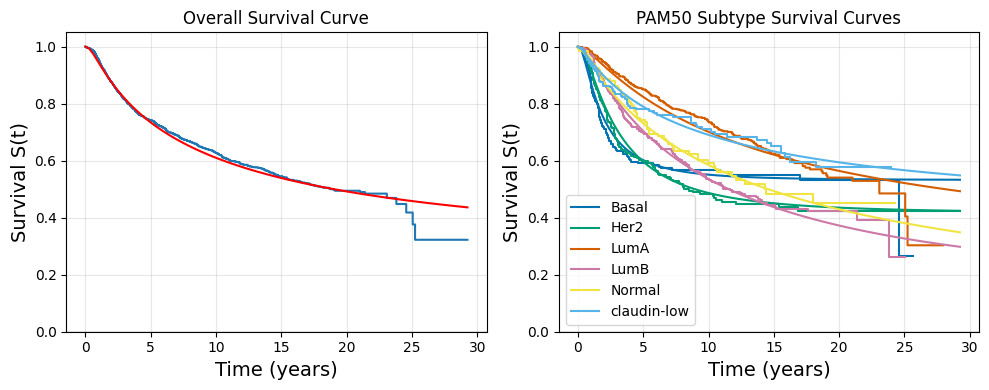

In [9]:
ts_grid = ln_summary3["ts_grid"].flatten()

ln_S_ts = ln_summary3["S_ts_train"]
ln_S_ts_avg = np.mean( ln_S_ts, axis = 1 )

fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (10,4))

colors = get_hex_from_style("seaborn-v0_8-colorblind", num_colors=8)

km = lifelines.KaplanMeierFitter()
km.fit(y, delta)
km.plot(ax = ax[0], ci_show = False, show_censors = False, legend = False, label = '_')
ax[0].plot(ts_grid, ln_S_ts_avg, color = "red")

ax[0].set_ylim(0, 1.05)
ax[0].set_title("Overall Survival Curve")
ax[0].axhline(0, color = 'gray', linestyle = '-', linewidth = 1)
ax[0].grid(True, alpha = 0.3)

ax[0].set_xlabel("Time (years)", fontsize = 14)
ax[0].set_ylabel("Survival S(t)", fontsize = 14)

unique_pam50_subtypes = np.sort( df_clean["pam50_subtype"].unique() )

for i, subtype in enumerate(unique_pam50_subtypes):
    subtype_patients = df_clean["pam50_subtype"] == subtype
    y_subtype = df_clean.loc[subtype_patients, "time"] / 12
    delta_subtype = df_clean.loc[subtype_patients, "delta"]

    ln_S_ts_subtype_avg = np.mean(ln_S_ts[:, subtype_patients], axis = 1)

    ax[1].plot(ts_grid, ln_S_ts_subtype_avg, color = colors[i])
    
    km = lifelines.KaplanMeierFitter()
    km.fit(y_subtype, delta_subtype)
    km.plot(ax = ax[1], ci_show = False, show_censors = False, label = subtype, color = colors[i])

ax[1].set_ylim(0, 1.05)
ax[1].set_title("PAM50 Subtype Survival Curves")
ax[1].axhline(0, color = 'gray', linestyle = '-', linewidth = 1)
ax[1].grid(True, alpha = 0.3)

ax[1].set_xlabel("Time (years)", fontsize = 14)
ax[1].set_ylabel("Survival S(t)", fontsize = 14)

fig.tight_layout()

fig.savefig('Images/pam50_survival_curves.png', format='png', dpi=300, bbox_inches='tight')
fig.savefig('Images/pam50_survival_curves.pdf', format='pdf', dpi=300, bbox_inches='tight')

plt.show()

In [11]:
ln_model1.save_model("../model_weights/Interpretability/ln_model_structure1")
ln_model3.save_model("../model_weights/Interpretability/ln_model_structure3")

Model successfully saved to ../model_weights/Interpretability/ln_model_structure1.weights.h5 and ../model_weights/Interpretability/ln_model_structure1_meta.pkl
Model successfully saved to ../model_weights/Interpretability/ln_model_structure3.weights.h5 and ../model_weights/Interpretability/ln_model_structure3_meta.pkl
